# Prácticas 05-06  (5%, 5%) Entrega Lección Semana 11, 17:30 horas
## Trabajo grupal
### Integrantes:

| Integrante                 | Correo institucional        |
| -------------------------- | --------------------------- |
| Jonathan Barrantes         | jbarrantes40180@ufide.ac.cr |
| Joy D. Chávez Pomacaja     | jchavez60736@ufide.ac.cr    |
| María de Jesús Peña García | mpena30226@ufide.ac.cr      |
| Abby Chavarría Bolaños     | achavarria70596@ufide.ac.cr |

# Predicción de la calidad del vino.

### 1. Importación de librerías y carga de los archivos

Se importan los datos con `sep=";"`, se verifica que ambos archivos tengan las mismas columnas originales y se une todo en una tabla. Se conserva el orden de los registros, sin eliminar duplicados.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

SEMILLA = 42
sns.set_theme(style="whitegrid")
base = Path.cwd()

rojos = pd.read_csv(base / "winequality-red.csv", sep=";")
blancos = pd.read_csv(base / "winequality-white.csv", sep=";")

assert list(rojos.columns) == list(blancos.columns), "Las columnas originales no coinciden."
assert "quality" in rojos.columns, "No se encontró la variable objetivo quality."

rojos["tipo_vino"] = "Rojo"
blancos["tipo_vino"] = "Blanco"
datos_originales = pd.concat([rojos, blancos], ignore_index=True)

print(f"Vino rojo: {len(rojos):,} | Vino blanco: {len(blancos):,} | Total: {len(datos_originales):,}")
print(f"Dimensiones del dataset unido: {datos_originales.shape}")
assert len(datos_originales) == 6497
assert datos_originales["tipo_vino"].isin(["Rojo", "Blanco"]).all()
display(datos_originales.head())

Vino rojo: 1,599 | Vino blanco: 4,898 | Total: 6,497
Dimensiones del dataset unido: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vino
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Rojo
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Rojo
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Rojo
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Rojo
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Rojo


### 2. Creación reproducible de valores faltantes

Los archivos originales no tienen nulos. Para practicar el preprocesamiento posterior se elimina aproximadamente **2% de las celdas de predictores numéricos**, mediante la semilla aleatoria 42. No se modifican `quality` ni `tipo_vino`; tampoco se imputan los nulos en esta fase. El total de celdas afectadas puede variar alrededor del 2% porque la selección es aleatoria.

In [25]:
print("Nulos originales:", int(datos_originales.isna().sum().sum()))
assert datos_originales.isna().sum().sum() == 0

datos = datos_originales.copy()
columnas_numericas = datos.select_dtypes(include="number").columns.drop("quality")

rng = np.random.default_rng(SEMILLA)
mascara = rng.random((len(datos), len(columnas_numericas))) < 0.02
datos.loc[:, columnas_numericas] = datos[columnas_numericas].mask(mascara)

nulos_por_columna = datos.isna().sum().to_frame("Nulos")
nulos_por_columna["Porcentaje (%)"] = (100 * nulos_por_columna["Nulos"] / len(datos)).round(2)
print("Nulos artificiales:", int(datos.isna().sum().sum()))
print("Porcentaje de celdas nulas de predictores numéricos:", round(100 * datos[columnas_numericas].isna().sum().sum() / datos[columnas_numericas].size, 2), "%")
assert datos["quality"].notna().all()
assert datos["tipo_vino"].notna().all()
display(nulos_por_columna)

ruta_salida = base / "winequality-combinado-con-nulos.csv"
datos.to_csv(ruta_salida, index=False)
print("Archivo combinado guardado:", ruta_salida.name)

Nulos originales: 0
Nulos artificiales: 1400
Porcentaje de celdas nulas de predictores numéricos: 1.96 %


,Nulos,Porcentaje (%)
fixed acidity,136,2.09
volatile acidity,121,1.86
citric acid,130,2.00
residual sugar,98,1.51
chlorides,126,1.94
free sulfur dioxide,114,1.75
total sulfur dioxide,163,2.51
density,121,1.86
pH,141,2.17
sulphates,125,1.92


Archivo combinado guardado: winequality-combinado-con-nulos.csv


### 3. Estructura y calidad inicial de los datos

Antes de analizar las distribuciones revisamos tamaño, nombres, tipos de columnas, frecuencias y presencia de nulos. Los valores faltantes se omiten automáticamente en las estadísticas descriptivas de Pandas, pero **no se reemplazan ni se eliminan registros**.

In [26]:
print("Dimensiones:", datos.shape)
print("Tipos de datos:")
display(datos.dtypes.to_frame("Tipo de dato"))
print("Resumen de valores no nulos:")
display(datos.count().to_frame("Registros disponibles"))
print("Primeras cinco filas del dataset con nulos:")
display(datos.head())

Dimensiones: (6497, 13)
Tipos de datos:


,Tipo de dato
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


Resumen de valores no nulos:


,Registros disponibles
fixed acidity,6361
volatile acidity,6376
citric acid,6367
residual sugar,6399
chlorides,6371
free sulfur dioxide,6383
total sulfur dioxide,6334
density,6376
pH,6356
sulphates,6372


Primeras cinco filas del dataset con nulos:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_vino
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Rojo
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Rojo
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Rojo
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Rojo
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,NaN,3.51,0.56,9.4,5,Rojo


### 4. Tablas de frecuencia

Se muestra la frecuencia absoluta y relativa del tipo de vino y de la calificación. La tabla cruzada sirve para observar cómo se distribuye `quality` en cada tipo de vino. `quality` es una calificación ordinal registrada como número; en la práctica se trata como variable objetivo de regresión.

In [27]:
frecuencia_tipo = datos["tipo_vino"].value_counts().rename_axis("Tipo de vino").to_frame("Frecuencia")
frecuencia_tipo["Porcentaje (%)"] = (100 * frecuencia_tipo["Frecuencia"] / len(datos)).round(2)
print("Frecuencia por tipo de vino:")
display(frecuencia_tipo)

frecuencia_calidad = datos["quality"].value_counts().sort_index().rename_axis("Calidad").to_frame("Frecuencia")
frecuencia_calidad["Porcentaje (%)"] = (100 * frecuencia_calidad["Frecuencia"] / len(datos)).round(2)
print("Frecuencia por calidad:")
display(frecuencia_calidad)

print("Tabla cruzada: tipo de vino × calidad (frecuencia absoluta):")
display(pd.crosstab(datos["tipo_vino"], datos["quality"]))
print("Tabla cruzada: distribución porcentual de calidad dentro de cada tipo:")
display((100 * pd.crosstab(datos["tipo_vino"], datos["quality"], normalize="index")).round(2))

Frecuencia por tipo de vino:


,Frecuencia,Porcentaje (%)
Tipo de vino,,
Blanco,4898,75.39
Rojo,1599,24.61


Frecuencia por calidad:


,Frecuencia,Porcentaje (%)
Calidad,,
3,30,0.46
4,216,3.32
5,2138,32.91
6,2836,43.65
7,1079,16.61
8,193,2.97
9,5,0.08


Tabla cruzada: tipo de vino × calidad (frecuencia absoluta):


quality,3,4,5,6,7,8,9
tipo_vino,,,,,,,
Blanco,20,163,1457,2198,880,175,5
Rojo,10,53,681,638,199,18,0


Tabla cruzada: distribución porcentual de calidad dentro de cada tipo:


quality,3,4,5,6,7,8,9
tipo_vino,,,,,,,
Blanco,0.41,3.33,29.75,44.88,17.97,3.57,0.1
Rojo,0.63,3.31,42.59,39.90,12.45,1.13,0.0


### 5. Resumen estadístico de variables numéricas

Las medidas de tendencia central y dispersión permiten comparar características con escalas muy diferentes. La media puede verse afectada por valores extremos; la mediana y los cuartiles permiten examinar la distribución con mayor robustez.

In [28]:
resumen = datos[list(columnas_numericas) + ["quality"]].describe().T
resumen = resumen.rename(columns={"count":"n", "mean":"Media", "std":"Desv. estándar", "min":"Mínimo", "25%":"Q1", "50%":"Mediana", "75%":"Q3", "max":"Máximo"})
print("Estadísticas descriptivas (sin imputar nulos):")
display(resumen.round(3))

print("Resumen de quality por tipo de vino:")
display(datos.groupby("tipo_vino")["quality"].agg(["count", "mean", "median", "std", "min", "max"]).round(3))

print("Medianas seleccionadas por tipo de vino:")
display(datos.groupby("tipo_vino")[["alcohol", "residual sugar", "volatile acidity"]].median().round(3))

Estadísticas descriptivas (sin imputar nulos):


,n,Media,Desv. estándar,Mínimo,Q1,Mediana,Q3,Máximo
fixed acidity,6361.0,7.217,1.297,3.800,6.400,7.000,7.700,15.900
volatile acidity,6376.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6367.0,0.319,0.146,0.000,0.250,0.310,0.390,1.660
residual sugar,6399.0,5.447,4.760,0.600,1.800,3.000,8.100,65.800
chlorides,6371.0,0.056,0.034,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6383.0,30.508,17.802,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6334.0,115.722,56.456,6.000,77.125,118.000,155.000,440.000
density,6376.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6356.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6372.0,0.532,0.149,0.220,0.430,0.510,0.600,2.000


Resumen de quality por tipo de vino:


,count,mean,median,std,min,max
tipo_vino,,,,,,
Blanco,4898,5.878,6.0,0.886,3,9
Rojo,1599,5.636,6.0,0.808,3,8


Medianas seleccionadas por tipo de vino:


,alcohol,residual sugar,volatile acidity
tipo_vino,,,
Blanco,10.4,5.2,0.26
Rojo,10.2,2.2,0.52


### 6. Histogramas de cada característica numérica

Los histogramas ayudan a observar la forma de las distribuciones, su concentración y posibles asimetrías. Se incluyen las 11 características originales y `quality`. Pandas excluye las celdas nulas de cada histograma, sin modificar el dataset.

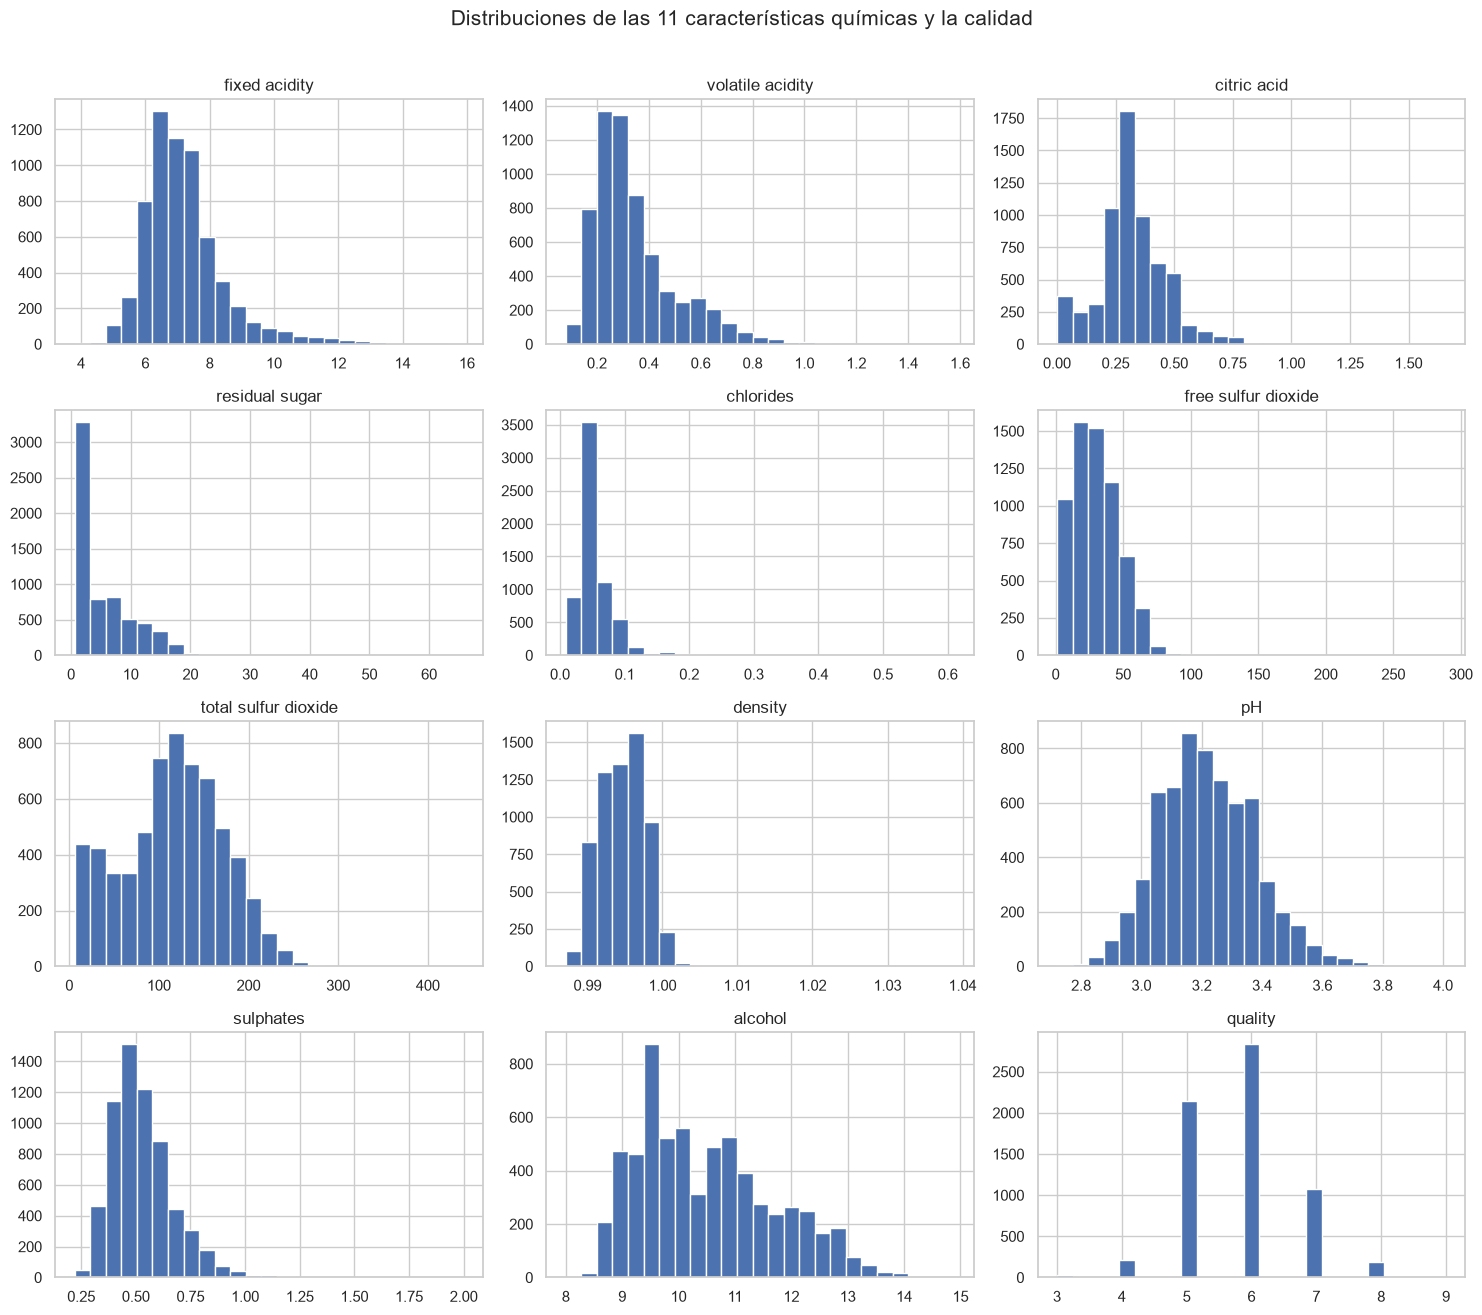

In [29]:
variables_hist = list(columnas_numericas) + ["quality"]
ejes = datos[variables_hist].hist(bins=25, figsize=(15, 13), layout=(4, 3), edgecolor="white")
plt.suptitle("Distribuciones de las 11 características químicas y la calidad", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

### 7. Boxplots para examinar variabilidad y posibles extremos

Los diagramas de caja resaltan mediana, cuartiles y observaciones fuera de los bigotes. **Un punto marcado como posible extremo no implica necesariamente un error**. Por ahora no se eliminan observaciones; el análisis numérico de valores extremos y correlaciones queda para el integrante 2.

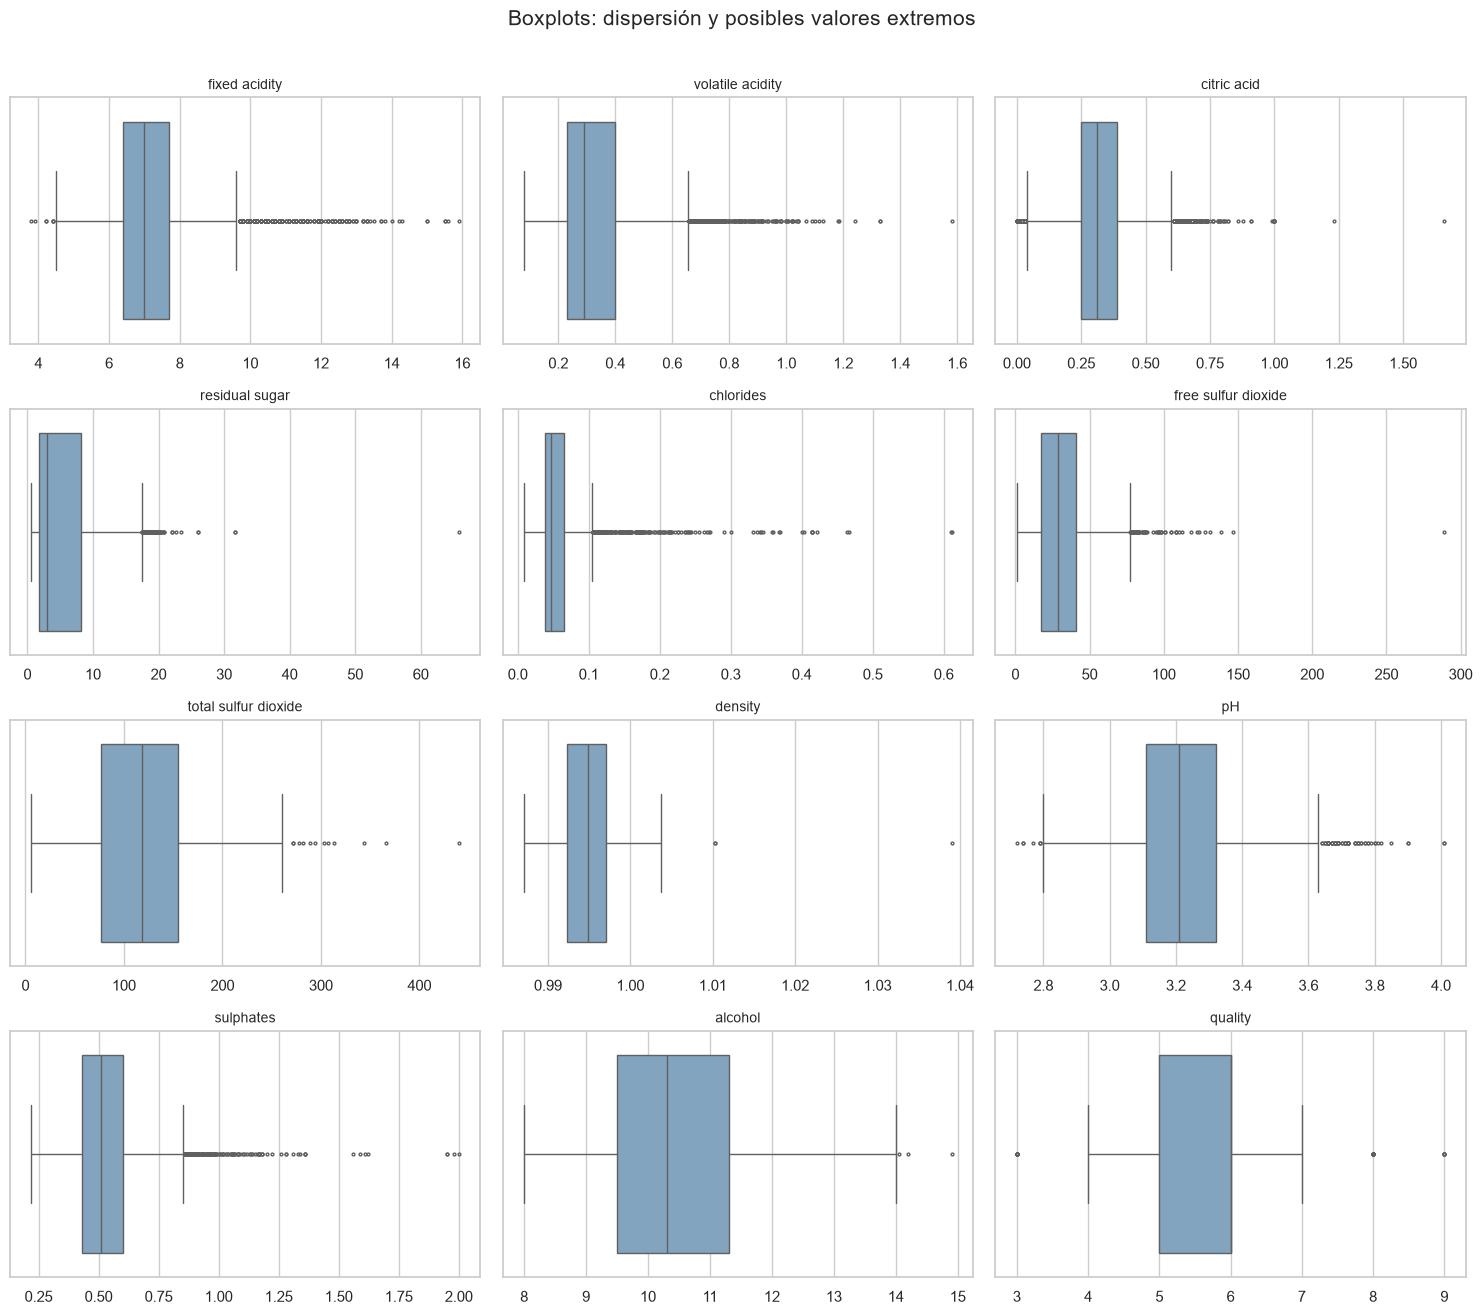

In [30]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for ax, columna in zip(axes.flat, variables_hist):
    sns.boxplot(x=datos[columna], ax=ax, color="#78A6C8", fliersize=2)
    ax.set_title(columna, fontsize=10)
    ax.set_xlabel("")
for ax in axes.flat[len(variables_hist):]:
    ax.axis("off")
plt.suptitle("Boxplots: dispersión y posibles valores extremos", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

### 8. Visualización básica de la composición de la muestra

El gráfico de barras de calidad facilita identificar las calificaciones más comunes y el número de vinos por tipo. Es un complemento descriptivo a las tablas de frecuencia anteriores.

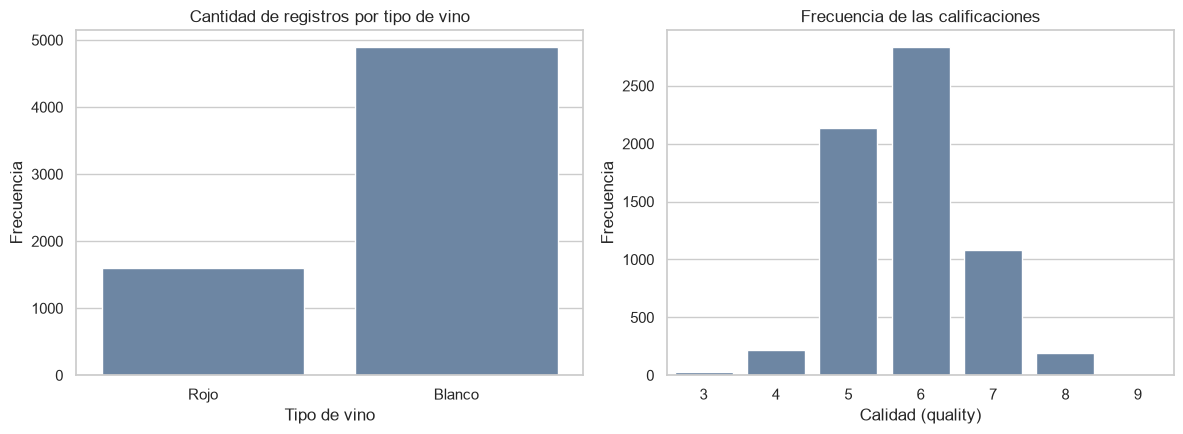

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(data=datos, x="tipo_vino", order=["Rojo", "Blanco"], ax=axes[0], color="#6485AC")
axes[0].set_title("Cantidad de registros por tipo de vino")
axes[0].set_xlabel("Tipo de vino")
axes[0].set_ylabel("Frecuencia")
sns.countplot(data=datos, x="quality", order=sorted(datos["quality"].unique()), ax=axes[1], color="#6485AC")
axes[1].set_title("Frecuencia de las calificaciones")
axes[1].set_xlabel("Calidad (quality)")
axes[1].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### 9. Análisis de correlaciones entre variables
La correlación de Pearson mide la dirección y la intensidad de la asociación lineal entre dos variables numéricas; sus valores van de −1 a +1. La matriz se calcula usando los registros disponibles en cada par de columnas, sin imputar los valores faltantes artificiales y sin utilizar la variable categórica tipo_vino.

El heatmap facilita identificar relaciones entre características químicas y la variable objetivo quality. Después se ordenan las correlaciones con quality por su valor absoluto. También se muestran las correlaciones por tipo de vino, ya que las relaciones del conjunto combinado no necesariamente son iguales dentro de cada grupo.

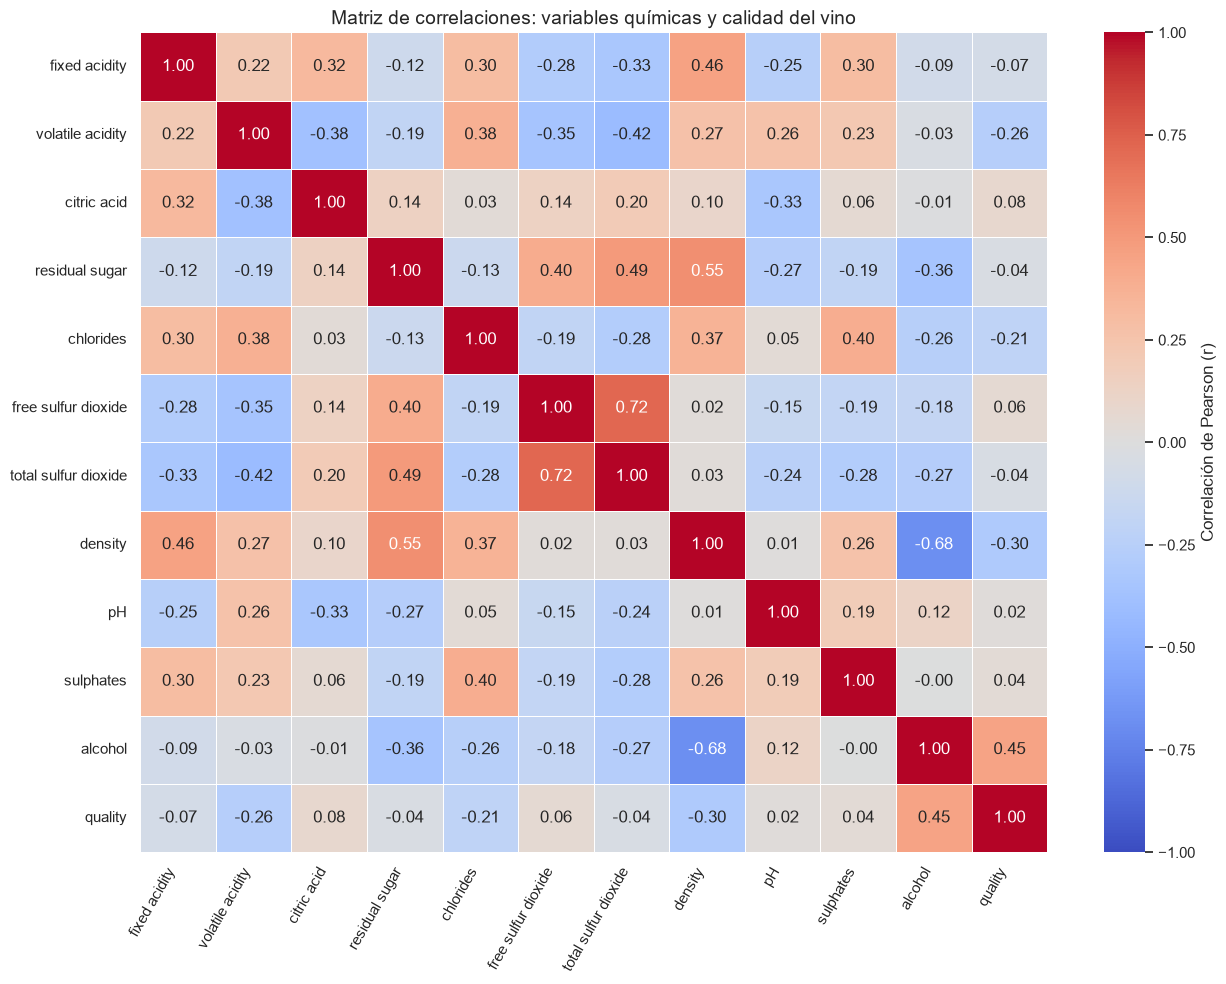

Correlaciones con quality ordenadas por magnitud absoluta:


,r con quality
alcohol,0.446
density,-0.305
volatile acidity,-0.264
chlorides,-0.205
citric acid,0.084
fixed acidity,-0.073
free sulfur dioxide,0.058
total sulfur dioxide,-0.040
sulphates,0.039
residual sugar,-0.037


Correlación con quality según tipo de vino:


,Blanco,Rojo
alcohol,0.438,0.476
density,-0.306,-0.170
volatile acidity,-0.190,-0.391
chlorides,-0.213,-0.135
citric acid,-0.012,0.228
fixed acidity,-0.112,0.131
free sulfur dioxide,0.009,-0.049
total sulfur dioxide,-0.174,-0.188
sulphates,0.054,0.249
residual sugar,-0.097,0.014


Relaciones entre otras características (ejemplos):
Dióxido de azufre libre vs. total: 0.722
Densidad vs. alcohol: -0.684


In [32]:
variables_correlacion = list(columnas_numericas) + ["quality"]
matriz_correlacion = datos[variables_correlacion].corr(method="pearson")

plt.figure(figsize=(13, 10))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.45,
    square=False,
    cbar_kws={"label": "Correlación de Pearson (r)"},
)
plt.title("Matriz de correlaciones: variables químicas y calidad del vino", fontsize=14)
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

correlaciones_calidad = (matriz_correlacion["quality"]
    .drop("quality")
    .sort_values(key=lambda serie: serie.abs(), ascending=False)
    .rename("r con quality")
    .to_frame())
print("Correlaciones con quality ordenadas por magnitud absoluta:")
display(correlaciones_calidad.round(3))

correlaciones_por_tipo = pd.DataFrame({
    tipo: grupo[variables_correlacion].corr(method="pearson")["quality"].drop("quality")
    for tipo, grupo in datos.groupby("tipo_vino")
})
print("Correlación con quality según tipo de vino:")
display(correlaciones_por_tipo.loc[correlaciones_calidad.index].round(3))

print("Relaciones entre otras características (ejemplos):")
print("Dióxido de azufre libre vs. total:", round(matriz_correlacion.loc["free sulfur dioxide", "total sulfur dioxide"], 3))
print("Densidad vs. alcohol:", round(matriz_correlacion.loc["density", "alcohol"], 3))

### 10. Identificación de posibles valores extremos
Los boxplots de la sección 7 permiten observar valores alejados de la distribución central. Para cuantificarlos, usamos el criterio exploratorio de Tukey: por cada atributo numérico, se señalan observaciones por debajo de Q1 − 1,5 × IQR o por encima de Q3 + 1,5 × IQR, donde IQR = Q3 − Q1.

Los valores faltantes se excluyen del cálculo. No se eliminan observaciones ni se imputan valores en esta etapa: un valor extremo puede corresponder a una medida legítima y requerir revisión de dominio antes de decidir el tratamiento.

In [33]:
filas_extremos = []
for columna in columnas_numericas:
    serie = datos[columna].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    rango_intercuartil = q3 - q1
    limite_inferior = q1 - 1.5 * rango_intercuartil
    limite_superior = q3 + 1.5 * rango_intercuartil
    cantidad_extremos = int(((serie < limite_inferior) | (serie > limite_superior)).sum())
    filas_extremos.append({
        "Variable": columna,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Posibles extremos": cantidad_extremos,
        "Porcentaje de datos válidos (%)": round(cantidad_extremos / len(serie) * 100, 2),
    })
tabla_extremos = pd.DataFrame(filas_extremos).sort_values("Posibles extremos", ascending=False)
print("Posibles valores extremos según la regla 1,5 × IQR (sin eliminarlos):")
display(tabla_extremos.round(3))

Posibles valores extremos según la regla 1,5 × IQR (sin eliminarlos):


,Variable,Límite inferior,Límite superior,Posibles extremos,Porcentaje de datos válidos (%)
2,citric acid,0.040,0.600,502,7.88
1,volatile acidity,-0.025,0.655,372,5.83
0,fixed acidity,4.450,9.650,353,5.55
4,chlorides,-0.003,0.106,277,4.35
9,sulphates,0.175,0.855,190,2.98
3,residual sugar,-7.650,17.550,117,1.83
8,pH,2.795,3.635,71,1.12
5,free sulfur dioxide,-19.000,77.000,61,0.96
6,total sulfur dioxide,-39.688,271.812,12,0.19
7,density,0.985,1.004,3,0.05


### 11. Interpretación de los resultados 
Composición del dataset. Se unieron 1.599 registros de vino rojo y 4.898 de vino blanco, para un total de 6.497 filas y 13 columnas (11 atributos químicos, quality y tipo_vino). El vino blanco representa aproximadamente 75,39% de la muestra, por lo que hay un desequilibrio entre tipos de vino que debe tenerse presente al comparar resultados y al decidir la estrategia de partición.

Valores faltantes. Los CSV originales no contenían datos nulos. Con SEMILLA = 42 se introdujeron 1.400 valores nulos, equivalentes a aproximadamente 1,96% de las celdas de los 11 predictores numéricos. Se conservaron completas la variable objetivo y la columna de tipo de vino. Estos valores nulos se manejarán después, únicamente con el conjunto de entrenamiento.

Calificaciones predominantes. Los valores de quality más frecuentes son 6 (2.836 vinos) y 5 (2.138 vinos); juntos representan aproximadamente 76,56% del conjunto. Las calificaciones más extremas son mucho menos frecuentes. La concentración de observaciones debe considerarse cuando se decida cómo evaluar los modelos.

Medidas numéricas y dispersión. Las variables no comparten la misma escala. Por ejemplo, la mediana de alcohol es aproximadamente 10,3 y la del azúcar residual es 3,0. El azúcar residual presenta asimetría positiva: su media es aproximadamente 5,45, mayor que su mediana. Los histogramas muestran la forma de estas distribuciones y los boxplots destacan observaciones que merecen revisión, pero no justifican su eliminación automática.

Diferencias descriptivas entre tipos de vino. La mediana de azúcar residual es aproximadamente 5,2 para blancos y 2,2 para rojos. La media de quality es aproximadamente 5,88 para blancos y 5,64 para rojos, aunque esta diferencia descriptiva no demuestra causalidad ni indica qué atributo la explica.

Correlaciones con la calidad. El atributo alcohol muestra la asociación lineal positiva más alta con quality (r ≈ +0,446). Entre las asociaciones negativas destacan density (r ≈ −0,305), volatile acidity (r ≈ −0,264) y chlorides (r ≈ −0,205). Dentro de los vinos rojos, volatile acidity tiene una relación negativa más intensa con la calidad (r ≈ −0,391) que dentro de los blancos (r ≈ −0,190). Esto confirma que conviene revisar las relaciones también por tipo de vino. Son asociaciones descriptivas y no indican efectos causales.

Relaciones entre predictores. Se observa una correlación positiva relativamente alta entre free sulfur dioxide y total sulfur dioxide (r ≈ +0,722), y negativa entre density y alcohol (r ≈ −0,684). Conviene considerar estas relaciones al elegir y evaluar modelos posteriores.

Valores extremos y estratificación. La tabla de Tukey identifica observaciones fuera de los límites intercuartílicos, sin afirmar que sean errores ni eliminarlas. Como hay más vinos blancos que rojos y la mayoría de quality se concentra en 5 y 6, se sugiere que el encargado de separar los datos evalúe una estratificación por tipo_vino y grupos de quality, comparándola con una división aleatoria.

Conclusión. La carga, unión, creación reproducible de nulos y el análisis exploratorio, incluidas las correlaciones y la revisión de posibles extremos, están completos. El archivo winequality-combinado-con-nulos.csv puede utilizarse en las siguientes fases. Los integrantes siguientes podrán utilizar estos hallazgos para dividir los datos y aplicar preprocesamiento sin fuga de información.

El ejercicio descrito a continuación será desarrollado a lo largo de varias prácticas. En este documento se enunciarán las actividades correspondientes a las prácticas 5 y 6.

## Propósito del ejercicio:

Aplicar técnicas de aprendizaje automático para predecir la calidad del vino en base a sus características químicas. Este es un problema de regresión, donde la variable objetivo (quality) es continua. Para lograrlo, se realizará un análisis exploratorio, se prepararán (preprocesarán) los datos para el entrenamiento, se entrenarán modelos para seleccionar el de mejor rendimiento, se afinará el modelo seleccionado y finalmente este se evaluará usando el conjunto de prueba.

## Propósito de las prácticas 5 y 6
Explorar y preprocesar el data set.

## Actividades

1. Análisis exploratorio inicial: 
    1. Distribuciones y relaciones: Utilizar tablas de frecuencias, resúmenes numéricos, resúmenes gráficos (Histogramas, Box-plots) para analizar la distribución de cada característica. Buscar posibles correlaciones. Identificar posibles atributos que deban ser considerados en la estratificación de los conjuntos de entrenamiento y prueba. Identificar valores extremos.
1. Separación de datos: Dividir el dataset en conjuntos de entrenamiento y prueba, si se aplica estratificación compárelos con los conjuntos que resultarían al dividirlos solo de forma aleatoria.
1. Preprocesamiento del conjunto de entrenamiento:
    1. Manejo de valores faltantes: Revisar si hay valores faltantes y aplicar una estrategia para manejarlos (por ejemplo, eliminación o imputación).
    1. Escalado: Usar técnicas de escalado (como normalización o estandarización) para escalar los datos numéricos y mejorar el desempeño de algunos modelos.
    1. Codificación de datos categóricas: Utilizar One-Hot Encoding para variables con categorías.
    1. Creación de nuevas características: Revisar la utilidad de generar nuevas variables.
2. Automatización del preprocesamiento: Usar "pipelines" y transformadores para automatizar los pasos del preprocesamiento del conjunto de entrenamiento   


## Descripción del Dataset:

En estas prácticas se utilizará el dataset de vinos (Wine Quality Dataset), que contiene información sobre diversas características químicas de los vinos y su calidad. El objetivo es predecir la calidad del vino utilizando las características proporcionadas. El dataset se compone de dos tipos de vino: vino rojo y vino blanco.

**Características del Dataset:**

El dataset contiene 12 variables, de las cuales 11 son características o atributos (variables predictoras) y una es la variable objetivo (la calidad del vino). Las variables se describen a continuación:

- Variables predictoras 
    - fixed acidity: Acidez fija del vino (valor numérico).
    - volatile acidity: Acidez volátil del vino (valor numérico).
    - citric acid: Cantidad de ácido cítrico en el vino (valor numérico).
    - residual sugar: Cantidad de azúcar residual en el vino (valor numérico).
    - chlorides: Nivel de cloruros en el vino (valor numérico).
    - free sulfur dioxide: Cantidad de dióxido de azufre libre (valor numérico).
    - total sulfur dioxide: Cantidad total de dióxido de azufre (valor numérico).
    - density: Densidad del vino (valor numérico).
    - pH: pH del vino (valor numérico).
    - sulphates: Nivel de sulfatos en el vino (valor numérico).
    - alcohol: Porcentaje de alcohol en el vino (valor numérico).

- Variable Objetivo:
    - quality: Calidad del vino medida en una escala del 0 al 10, siendo 0 la menor calidad y 10 la mayor. Esta es la variable que se debe predecir utilizando los datos proporcionados.

El data set está separado en dos archivos (uno para vino rojo y otro para vino blanco). Únalos en un solo archivo y agregue una columna categórica para identificar el tipo de vino con los siguientes valores: "Blanco" y "Rojo".

Borre aleatoriamente algunos valores en las columnas de algunos registros para generar nulos.

Referencia del data set:
P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. 
  Modeling wine preferences by data mining from physicochemical properties.
  In Decision Support Systems, Elsevier, 47(4):547-553. ISSN: 0167-9236.


### En próximas prácticas .....
Usando el pipeline de preprocesamiento se entrenarán varios modelos, se seleccionará, se afinará y se probará el mejor.

In [34]:
## Ingrese su código a partir de esta celda